# 01 · Exploratory data analysis — M5 subset

Questions this notebook answers before any modelling:

1. What does aggregate demand look like (trend, seasonality, holidays)?
2. How intermittent is SKU-level demand? (drives model choice and the Tweedie loss)
3. Do prices, SNAP days and events move demand? (drives feature engineering)

Data: the validated demand table produced by `demand-engine ingest` (`data/processed/sales.parquet`).

In [1]:
from pathlib import Path
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Notebooks live in notebooks/; run everything relative to the repository root.
if Path.cwd().name == "notebooks":
    os.chdir("..")
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})

from demand_engine.data.transform import classify_intermittency

df = pd.read_parquet("data/processed/sales.parquet")
print(f"{df['unique_id'].nunique():,} series · {df['item_id'].nunique()} items · "
      f"{df['store_id'].nunique()} stores · {df['ds'].min().date()} → {df['ds'].max().date()} · {len(df):,} rows")
df.head()

1,961 series · 498 items · 4 stores · 2014-05-24 → 2016-05-22 · 1,371,549 rows


,unique_id,item_id,dept_id,cat_id,store_id,state_id,ds,y,sell_price,wm_yr_wk,wday,month,year,event_name_1,event_type_1,snap
0,FOODS_1_011_CA_1,FOODS_1_011,FOODS_1,FOODS,CA_1,CA,2014-07-02,4.0,2.48,11422,5,7,2014,none,none,1
1,FOODS_1_011_CA_1,FOODS_1_011,FOODS_1,FOODS,CA_1,CA,2014-07-03,5.0,2.48,11422,6,7,2014,none,none,1
2,FOODS_1_011_CA_1,FOODS_1_011,FOODS_1,FOODS,CA_1,CA,2014-07-04,3.0,2.48,11422,7,7,2014,IndependenceDay,National,1
3,FOODS_1_011_CA_1,FOODS_1_011,FOODS_1,FOODS,CA_1,CA,2014-07-05,1.0,2.48,11423,1,7,2014,none,none,1
4,FOODS_1_011_CA_1,FOODS_1_011,FOODS_1,FOODS,CA_1,CA,2014-07-06,1.0,2.48,11423,2,7,2014,none,none,1


## 1. Aggregate demand over time

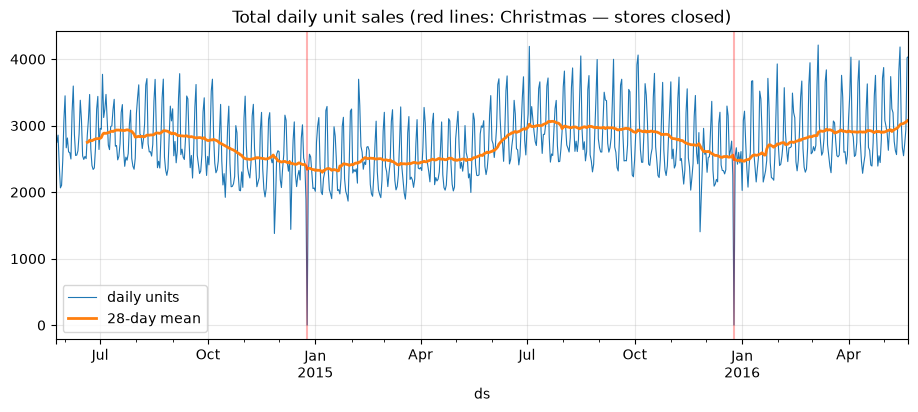

In [2]:
daily = df.groupby("ds")["y"].sum()
ax = daily.plot(lw=0.8, label="daily units")
daily.rolling(28).mean().plot(ax=ax, lw=2, label="28-day mean")
for d in daily[daily < daily.median() * 0.2].index:
    ax.axvline(d, color="red", alpha=0.3)
ax.set_title("Total daily unit sales (red lines: Christmas — stores closed)")
ax.legend();

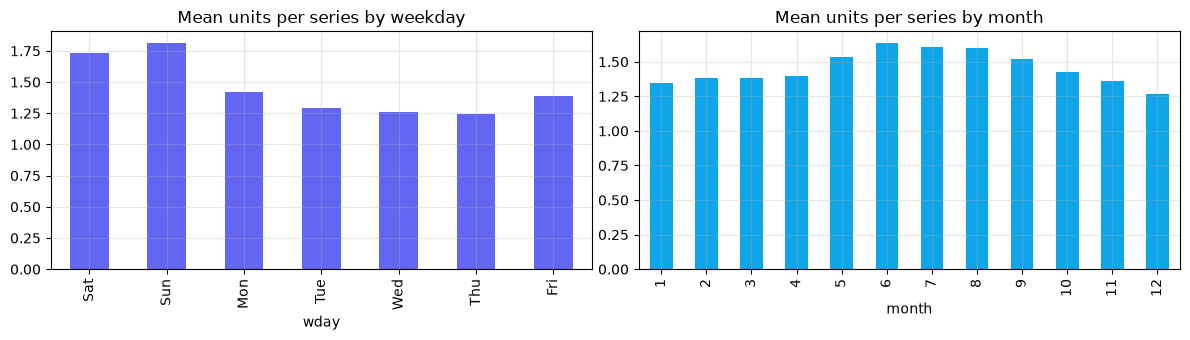

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
weekday = df.groupby("wday")["y"].mean().rename(index={1: "Sat", 2: "Sun", 3: "Mon", 4: "Tue", 5: "Wed", 6: "Thu", 7: "Fri"})
weekday.plot.bar(ax=axes[0], color="#6366f1", title="Mean units per series by weekday")
df.groupby("month")["y"].mean().plot.bar(ax=axes[1], color="#0ea5e9", title="Mean units per series by month")
plt.tight_layout()

**Observation:** strong weekly seasonality (weekend days sell ≈ 34 % more than weekdays),
mild annual seasonality, store closures at Christmas. → calendar features and a weekly seasonal component are essential.

## 2. Intermittency

class
intermittent    0.731
lumpy           0.146
smooth          0.092
erratic         0.031
Name: proportion, dtype: float64

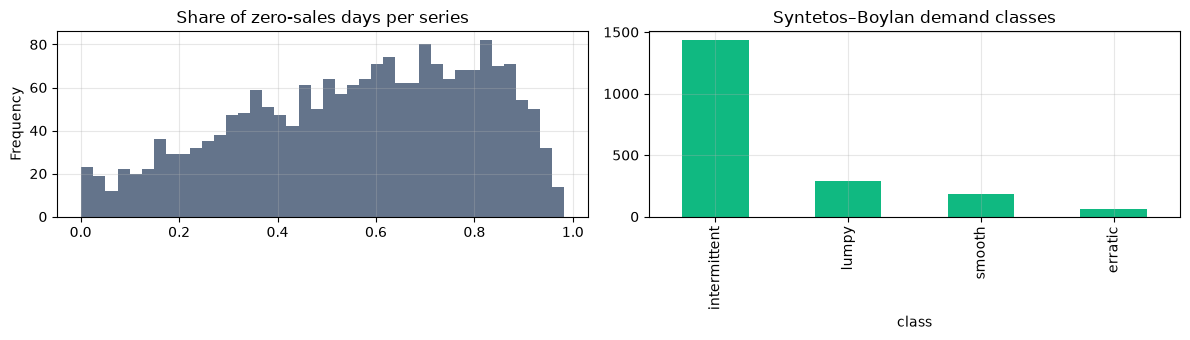

In [4]:
per_series = df.groupby("unique_id")["y"].agg(["mean", lambda s: (s == 0).mean()])
per_series.columns = ["mean_daily", "zero_share"]
per_series["class"] = df.groupby("unique_id")["y"].apply(lambda s: classify_intermittency(s.to_numpy(dtype=float)))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
per_series["zero_share"].plot.hist(bins=40, ax=axes[0], color="#64748b", title="Share of zero-sales days per series")
per_series["class"].value_counts().plot.bar(ax=axes[1], color="#10b981", title="Syntetos–Boylan demand classes")
plt.tight_layout()
per_series["class"].value_counts(normalize=True).round(3)

**Observation:** ≈ 88 % of series are classified *intermittent* or *lumpy* — they sell
nothing on a large share of days. Squared-error models fitted per series struggle here; we
include Croston/TSB and train LightGBM with a Tweedie (compound Poisson–gamma) loss.

## 3. Drivers: price, SNAP, events

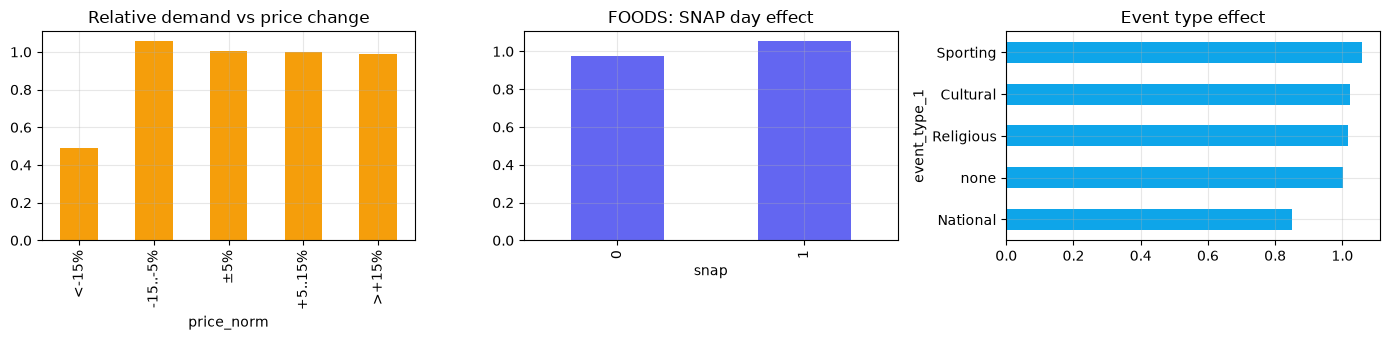

In [5]:
d = df.copy()
d["price_norm"] = d["sell_price"] / d.groupby("unique_id")["sell_price"].transform("median")
d["rel_demand"] = d["y"] / d.groupby("unique_id")["y"].transform("mean").replace(0, np.nan)
bins = pd.cut(d["price_norm"], [0, 0.85, 0.95, 1.05, 1.15, 10], labels=["<-15%", "-15..-5%", "±5%", "+5..15%", ">+15%"])
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
d.groupby(bins, observed=True)["rel_demand"].mean().plot.bar(ax=axes[0], color="#f59e0b", title="Relative demand vs price change")
d[d["cat_id"] == "FOODS"].groupby("snap")["rel_demand"].mean().plot.bar(ax=axes[1], color="#6366f1", title="FOODS: SNAP day effect")
d.groupby("event_type_1")["rel_demand"].mean().sort_values().plot.barh(ax=axes[2], color="#0ea5e9", title="Event type effect")
plt.tight_layout()

**Conclusions for modelling**

* **Price effects are not monotone.** Moderate discounts (5–15 % below an item's usual
  price) lift demand by ≈ 6 %, but the rare days with prices > 15 % below usual (≈ 1 % of
  rows) coincide with *half* the normal demand — typically clearance / end-of-life pricing,
  not promotions. Price must therefore be modelled *relative to the item's own history*
  (`price_norm`, `price_change_7`) and combined with recent-sales features, letting the
  tree model learn the non-linear pattern instead of assuming "cheaper = more".
* SNAP days lift FOODS sales; sporting and cultural events raise demand slightly, while
  national holidays (incl. Christmas closures) reduce it. All are known in advance, so they
  are leakage-free features for future dates.
* Heavy intermittency → Tweedie loss, intermittent-demand baselines, scale-free metrics (RMSSE).
* Weekly seasonality → seasonal naive and ETS(A,N,A) baselines, weekday features.